# SARIMAX — Previsão do Preço Mensal do Arroz com o Dólar

**TCC — Sistemas de Informação | PUCRS**
Bruno Origem Noronha

Este notebook implementa o **SARIMAX**: o mesmo modelo SARIMA do *baseline*, com uma **variável exógena** (explicativa).
O "X" do nome vem de *eXogenous*.

- **Variável alvo (y, endógena):** preço do arroz em reais (`preco_brl`)
- **Variável exógena (X):** cotação do dólar (`dolar_venda`)

O objetivo é responder: **saber o valor do dólar melhora a previsão do preço do arroz?**
Para isso, usamos exatamente os mesmos parâmetros e a mesma divisão de dados do SARIMA; a única diferença é o dólar.

Roteiro:
1. Carregamento, unificação por data e divisão dos dados (80% treino / 20% teste)
2. Variável exógena e teste de estacionariedade (ADF)
3. Ajuste do modelo SARIMAX
4. Previsão no teste e métricas (RMSE, MAE, MAPE)
5. Gráfico final, exportação e comparação com o SARIMA

In [1]:
# Bibliotecas
import os
import warnings
warnings.filterwarnings("ignore")   # esconde avisos internos das bibliotecas, para a saída ficar limpa

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller           # teste de estacionariedade
from statsmodels.tsa.statespace.sarimax import SARIMAX   # modelo SARIMAX

# Pasta onde salvamos o gráfico e as métricas
PASTA_SAIDA = "outputs"
os.makedirs(PASTA_SAIDA, exist_ok=True)

## 1. Carregamento, unificação e divisão dos dados

- Lemos **dois arquivos**: o preço do arroz e a cotação do dólar, ambos **diários**.
- Unimos as duas tabelas pela **data** (`join` com `how="inner"`): só ficam os dias que existem **nas duas** bases. Assim, y e X cobrem exatamente o mesmo período.
- Calculamos a **média de cada mês** (`resample("MS")`), como no SARIMA (sazonalidade de 12 meses).
- A divisão é **cronológica**: os primeiros 80% dos meses viram treino e os 20% finais viram teste.
  É a mesma divisão do SARIMA, o que permite comparar os dois modelos de forma justa.

In [2]:
# Lê os dois CSVs, usando a coluna "data" como índice de tempo
arroz = pd.read_csv("../data/processed/preco_arroz_limpo.csv", parse_dates=["data"], index_col="data")
dolar = pd.read_csv("../data/processed/dolar_limpo.csv",       parse_dates=["data"], index_col="data")

# Une as duas bases pela data (só os dias presentes nas duas) e transforma em média mensal
dados = arroz[["preco_brl"]].join(dolar[["dolar_venda"]], how="inner")
dados = dados.resample("MS").mean().dropna()

y = dados["preco_brl"]     # variável alvo (endógena)
X = dados[["dolar_venda"]] # variável exógena (em formato de tabela, como o SARIMAX espera)

# Divisão 80% treino / 20% teste, respeitando a ordem do tempo
corte = int(len(dados) * 0.80)
y_treino, y_teste = y.iloc[:corte], y.iloc[corte:]
X_treino, X_teste = X.iloc[:corte], X.iloc[corte:]

print(f"Total : {len(dados)} meses ({dados.index[0]:%m/%Y} a {dados.index[-1]:%m/%Y})")
print(f"Treino: {len(y_treino)} meses ({y_treino.index[0]:%m/%Y} a {y_treino.index[-1]:%m/%Y})")
print(f"Teste : {len(y_teste)} meses ({y_teste.index[0]:%m/%Y} a {y_teste.index[-1]:%m/%Y})")

Total : 220 meses (01/2008 a 04/2026)
Treino: 176 meses (01/2008 a 08/2022)
Teste : 44 meses (09/2022 a 04/2026)


## 2. Variável exógena e teste de estacionariedade (ADF)

### Por que o dólar?

O arroz é uma *commodity* negociada no mercado internacional, com preços de referência em dólar:

- **Exportação:** quando o real se desvaloriza (dólar sobe), exportar fica mais vantajoso. Parte da oferta vai para fora e o preço interno tende a subir.
- **Importação:** com o dólar alto, o arroz importado fica mais caro, o que também sustenta o preço interno.
- **Custos de produção:** fertilizantes, defensivos e combustíveis são cotados em dólar, e encarecem a produção.

Por isso, espera-se uma **relação positiva**: dólar mais alto, arroz mais caro.

### Estacionariedade

Como no SARIMA, aplicamos o teste **ADF** (H₀: a série **não** é estacionária; **p-valor < 0,05** → estacionária)
ao preço do arroz e ao dólar, na série original e na **1ª diferença**. Usamos só o treino.

In [3]:
def teste_adf(s, nome):
    p_valor = adfuller(s)[1]   # o 2º item do resultado é o p-valor
    conclusao = "estacionária" if p_valor < 0.05 else "NÃO estacionária"
    print(f"{nome:<24} p-valor = {p_valor:.4f}  ->  {conclusao}")

teste_adf(y_treino,                          "Arroz — original")
teste_adf(y_treino.diff().dropna(),          "Arroz — 1ª diferença")
teste_adf(X_treino["dolar_venda"],                 "Dólar — original")
teste_adf(X_treino["dolar_venda"].diff().dropna(), "Dólar — 1ª diferença")

Arroz — original         p-valor = 0.7249  ->  NÃO estacionária
Arroz — 1ª diferença     p-valor = 0.0000  ->  estacionária
Dólar — original         p-valor = 0.8710  ->  NÃO estacionária
Dólar — 1ª diferença     p-valor = 0.0000  ->  estacionária


**Leitura:** as duas séries originais não são estacionárias, mas as primeiras diferenças são. Por isso usamos **d = 1**.

O SARIMAX aplica essa diferenciação ao modelo inteiro, então o efeito do dólar é estimado sobre as **variações**
(quanto o preço do arroz muda quando o dólar muda), e não sobre os níveis. Isso evita a **regressão espúria**:
duas séries que só sobem com o tempo parecem relacionadas mesmo sem ter relação real.

## 3. Ajuste do modelo SARIMAX

O modelo é **SARIMAX(p, d, q)(P, D, Q, s)** com uma variável exógena. Os parâmetros são **os mesmos do SARIMA**,
para que a única diferença entre os dois modelos seja o dólar:

| Parâmetro | Valor | Significado |
|---|---|---|
| **p** | 2 | usa os preços dos **2 meses anteriores** (parte autorregressiva) |
| **d** | 1 | **1 diferenciação** para tornar a série estacionária (resultado do ADF) |
| **q** | 0 | sem termo de média móvel dos erros recentes |
| **P** | 1 | usa o preço do **mesmo mês do ano anterior** (autorregressivo sazonal) |
| **D** | 1 | **1 diferenciação sazonal** (compara cada mês com o mesmo mês do ano anterior) |
| **Q** | 1 | corrige pelo erro do **mesmo mês do ano anterior** (média móvel sazonal) |
| **s** | 12 | ciclo sazonal de **12 meses** (dados mensais) |
| **exog** | dólar | cotação média do dólar no mês, que entra como **variável explicativa** |

Na prática, o modelo é uma **regressão do preço do arroz sobre o dólar**, em que o erro dessa regressão segue um SARIMA.
O resultado traz um **coeficiente para o dólar** (linha `dolar_venda` do resumo):

- **sinal** do coeficiente: positivo confirma que dólar maior → arroz mais caro;
- **P>|z|** (p-valor): abaixo de 0,05 indica que o efeito do dólar é estatisticamente significativo.

O modelo é ajustado **apenas com o treino**.

In [4]:
ORDEM         = (2, 1, 0)       # (p, d, q)
ORDEM_SAZONAL = (1, 1, 1, 12)   # (P, D, Q, s)

modelo = SARIMAX(endog=y_treino, exog=X_treino, order=ORDEM, seasonal_order=ORDEM_SAZONAL)
resultado = modelo.fit(disp=False)   # disp=False esconde as mensagens da otimização

print(resultado.summary())

# Destaque do efeito do dólar
coef   = resultado.params["dolar_venda"]
p_coef = resultado.pvalues["dolar_venda"]
print(f"\nCoeficiente do dólar = {coef:.2f}  (p-valor = {p_coef:.4f})")
if p_coef < 0.05:
    print(f"Significativo: cada R$ 1,00 a mais no dólar muda a saca de arroz em R$ {coef:.2f}, em média.")
else:
    print("NÃO significativo (p-valor >= 0,05): não há evidência de que o dólar ajude a explicar o preço do arroz neste modelo.")

                                      SARIMAX Results                                       
Dep. Variable:                            preco_brl   No. Observations:                  176
Model:             SARIMAX(2, 1, 0)x(1, 1, [1], 12)   Log Likelihood                -403.992
Date:                              Thu, 22 Oct 2026   AIC                            819.984
Time:                                      12:36:31   BIC                            838.547
Sample:                                  01-01-2008   HQIC                           827.520
                                       - 08-01-2022                                         
Covariance Type:                                opg                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
dolar_venda    -0.6110      1.632     -0.374      0.708      -3.810       2.588
ar.L1           

## 4. Previsão no teste e métricas

O modelo prevê todos os meses do teste de uma só vez, sem ter visto o preço do arroz nesses meses (*out-of-sample*).

Diferença em relação ao SARIMA: para prever, o SARIMAX **precisa do valor do dólar em cada mês futuro**.
Por isso passamos `exog=X_teste`.

> **Atenção (limitação):** aqui usamos o dólar **real** observado no período de teste. Isso mede o quanto o dólar
> *explica* o preço do arroz. Numa previsão de verdade o dólar futuro também seria desconhecido e precisaria ser
> estimado, o que acrescentaria erro.

Métricas (as mesmas do SARIMA):

| Métrica | O que mede |
|---|---|
| **RMSE** | raiz do erro quadrático médio, em R\$; pune mais os erros grandes |
| **MAE** | erro absoluto médio, em R\$; "em média, erramos X reais por mês" |
| **MAPE** | erro percentual médio; "em média, erramos X% do preço" |

In [5]:
# Previsão para os meses do teste, informando o dólar desses meses
previsao  = resultado.get_forecast(steps=len(y_teste), exog=X_teste)
y_prev    = previsao.predicted_mean
intervalo = previsao.conf_int(alpha=0.05)   # limites inferior e superior (95%)

# Métricas calculadas diretamente pelas fórmulas
erro = y_teste - y_prev
rmse = np.sqrt(np.mean(erro ** 2))
mae  = np.mean(np.abs(erro))
mape = np.mean(np.abs(erro / y_teste)) * 100

print(f"RMSE = R$ {rmse:.2f}")
print(f"MAE  = R$ {mae:.2f}")
print(f"MAPE = {mape:.2f}%")

RMSE = R$ 24.54
MAE  = R$ 21.21
MAPE = 25.44%


## 5. Gráfico final, exportação e comparação com o SARIMA

### 5.1 Gráfico: Real vs. Previsão SARIMAX

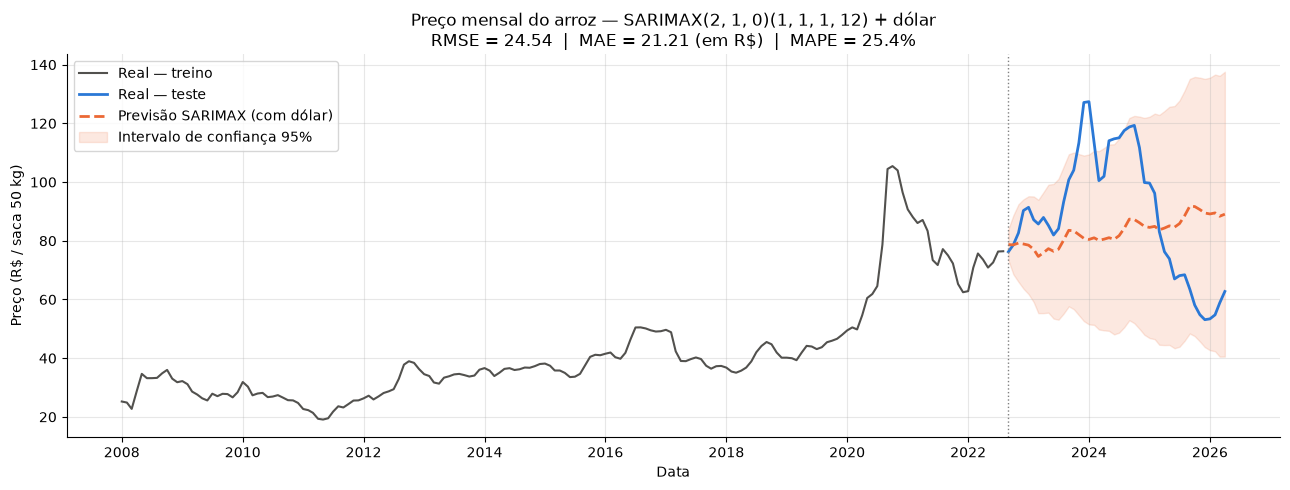

In [6]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(y_treino, color="#52514e", lw=1.5, label="Real — treino")
ax.plot(y_teste,  color="#2a78d6", lw=2,   label="Real — teste")
ax.plot(y_prev,   color="#eb6834", lw=2, ls="--", label="Previsão SARIMAX (com dólar)")
ax.fill_between(intervalo.index, intervalo.iloc[:, 0], intervalo.iloc[:, 1],
                color="#eb6834", alpha=0.15, label="Intervalo de confiança 95%")
ax.axvline(y_teste.index[0], color="gray", ls=":", lw=1)   # linha do corte treino/teste

ax.set_title(f"Preço mensal do arroz — SARIMAX{ORDEM}{ORDEM_SAZONAL} + dólar\n"
             f"RMSE = {rmse:.2f}  |  MAE = {mae:.2f} (em R$)  |  MAPE = {mape:.1f}%")
ax.set_xlabel("Data")
ax.set_ylabel("Preço (R$ / saca 50 kg)")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left")

plt.tight_layout()
plt.savefig(f"{PASTA_SAIDA}/sarimax_previsao.png", dpi=150)
plt.show()

### 5.2 Exportação das métricas

Salvamos as métricas no mesmo formato do SARIMA, para montar a tabela comparativa com XGBoost e LSTM.

In [7]:
pd.DataFrame({"modelo": ["SARIMAX"], "RMSE": [rmse], "MAE": [mae], "MAPE": [mape]}) \
  .round(2).to_csv(f"{PASTA_SAIDA}/metricas_sarimax.csv", index=False)

print(f"Métricas salvas em {PASTA_SAIDA}/metricas_sarimax.csv")

Métricas salvas em outputs/metricas_sarimax.csv


### 5.3 Tabela comparativa: SARIMA (baseline) vs. SARIMAX (com dólar)

Lemos as métricas do SARIMA (geradas pelo notebook `sarima_arroz.ipynb`) e colocamos lado a lado.
Nas três métricas, **quanto menor, melhor**. A última linha mostra a **variação percentual** do SARIMAX em relação ao SARIMA:
valores **negativos** significam que o dólar **reduziu o erro**.

In [8]:
sarima  = pd.read_csv(f"{PASTA_SAIDA}/metricas_sarima.csv")
sarimax = pd.read_csv(f"{PASTA_SAIDA}/metricas_sarimax.csv")

tabela = pd.concat([sarima, sarimax]).set_index("modelo")
tabela.index = ["SARIMA (baseline)", "SARIMAX (com dólar)"]

# Variação % do SARIMAX em relação ao SARIMA
tabela.loc["Variação (%)"] = (tabela.iloc[1] / tabela.iloc[0] - 1) * 100

tabela.round(2)

,RMSE,MAE,MAPE
SARIMA (baseline),24.51,21.20,25.39
SARIMAX (com dólar),24.54,21.21,25.44
Variação (%),0.12,0.05,0.20


## Conclusão

- O **coeficiente do dólar não foi estatisticamente significativo** (p-valor bem acima de 0,05), e o sinal estimado nem foi o positivo esperado.
- As métricas do SARIMAX ficaram **praticamente iguais** às do SARIMA (diferença abaixo de 1%).
- **Interpretação:** depois de considerar a própria história do preço (termos AR e sazonais), a cotação do dólar **no mesmo mês**
  não acrescenta informação útil para prever o preço do arroz neste período. Isso reforça o SARIMA como *baseline*
  e motiva os modelos não lineares (XGBoost e LSTM), que podem captar relações mais complexas e com defasagens.